# Environment — Face/Voice Main Pipeline + Experimental Fingerprint Bonus


In [ ]:
import sys
import subprocess
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "numpy", "pandas", "matplotlib", "scikit-learn", "scikit-image",
    "opencv-python-headless>=4.8,<5", "librosa", "soundfile", "joblib", "pillow"
])

0

## 1.2 Libraries

In [ ]:
from pathlib import Path
import hashlib
import inspect
import importlib.util
from importlib.metadata import version
import json
import shutil
import zipfile
import base64
from functools import lru_cache
import cv2
import librosa
import soundfile as sf
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from skimage.feature import hog, local_binary_pattern
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay
)
from IPython.display import display, Javascript
from google.colab import files, output
from IPython.display import Audio

## 1.3 Project Settings

In [ ]:
SEED = 42
EXPECTED_USERS = 4
COMMANDS = ["open", "close", "status"]
SPLITS = ["train", "val", "test"]
USE_FINGERPRINT = False  # Operational authorization ignores simulated fingerprints; bonus evaluation remains enabled
COMMAND_MIN_SCORE = 0.50
RUN_LIVE = True
ROOT = Path("/content/team_biometrics")
INPUT = ROOT / "input"
OUT = ROOT / "outputs"
INPUT.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
assert shutil.which("ffmpeg"), "FFmpeg is required. Use a standard Colab runtime."

## Environment — 2. Upload and Check the Two Datasets

In [ ]:
def zip_types(path):
    try:
        with zipfile.ZipFile(path) as archive:
            names = [name.lower() for name in archive.namelist()]
        videos = any(Path(name).suffix in {".mp4", ".mov", ".avi", ".mkv", ".webm"} for name in names)
        prints = any(Path(name).suffix in {".tif", ".tiff"} for name in names)
        return videos, prints
    except zipfile.BadZipFile:
        return False, False

# Deduplicate any double-uploaded files in /content first
for duplicate in Path("/content").glob("* (1).zip"):
    try:
        duplicate.unlink()
    except FileNotFoundError:
        pass

archives = list(Path("/content").glob("*.zip"))
if not any(zip_types(p)[0] for p in archives) or not any(zip_types(p)[1] for p in archives):
    print("Select the team video ZIP and the FVC2002 fingerprint ZIP.")
    uploaded = files.upload()
    del uploaded
    archives = list(Path("/content").glob("*.zip"))

team_archives = sorted(list({p.resolve() for p in archives if zip_types(p)[0]}))
fp_archives = sorted(list({p.resolve() for p in archives if zip_types(p)[1] and not zip_types(p)[0]}))

# If duplicates still exist, we gracefully take the first one instead of crashing
assert len(team_archives) >= 1, "Please upload the team video ZIP to /content."
assert len(fp_archives) >= 1, "Please upload the FVC2002 ZIP containing Db1_a TIFF images to /content."

team_archives = [team_archives[0]]
fp_archives = [fp_archives[0]]

Select the team video ZIP and the FVC2002 fingerprint ZIP.


Saving team dataset-20261109T222612Z-1-001.zip to team dataset-20261109T222612Z-1-001 (1).zip


## 2.2 Extract Datasets

In [ ]:

def extract_archive(path, destination):
    if destination.exists():
        shutil.rmtree(destination)
    destination.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(path) as archive:
        for item in archive.infolist():
            target = (destination / item.filename).resolve()
            assert target.is_relative_to(destination.resolve()), "Unsafe ZIP path."
        assert archive.testzip() is None, "Corrupted ZIP file."
        archive.extractall(destination)

extract_archive(team_archives[0], INPUT / "team")
extract_archive(fp_archives[0], INPUT / "fingerprints")


## 2.3 Check Team Recordings

In [ ]:
rows = []
ignored_files = []
for path in sorted((INPUT / "team").rglob("*")):
    if path.suffix.lower() not in {
        ".mp4", ".mov", ".avi", ".mkv", ".webm"
    }:
        continue
    if "__MACOSX" in path.parts or path.name.startswith("."):
        continue
    command = next(
        (
            name for name in COMMANDS
            if path.stem.lower().startswith(name)
        ),
        None
    )
    if command is None:
        ignored_files.append(str(path))
        continue
    split = path.parent.name.lower()
    user = path.parent.parent.name
    assert split in SPLITS, f"Invalid split: {path}"
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    rows.append({
        "user_id": user,
        "command": command,
        "split": split,
        "original_split": split,
        "recording_id": f"{command}_{digest[:16]}",
        "video_path": str(path),
        "sha256": digest
    })
team_df = pd.DataFrame(rows)
assert not team_df.empty, "No valid videos found."
owners = team_df.groupby("sha256")["user_id"].nunique()
assert owners.max() == 1, "Identical videos assigned to different users."
team_df = team_df.drop_duplicates(
    "sha256"
).reset_index(drop=True)
if ignored_files:
    display(pd.DataFrame({"IgnoredFile": ignored_files}))

In [ ]:
USERS = sorted(team_df["user_id"].unique())
assert len(USERS) == EXPECTED_USERS
assert "team_user04" in USERS
for command in COMMANDS:
    group = team_df[
        (team_df["user_id"] == "team_user04")
        & (team_df["command"] == command)
    ].sort_values("sha256")
    group = group.sample(frac=1, random_state=SEED)
    count = len(group)
    assert count >= 3, f"Not enough unique recordings: {command}"
    n_val = max(1, count // 5)
    n_test = max(1, count // 5)
    n_train = count - n_val - n_test
    assignments = (
        ["train"] * n_train
        + ["val"] * n_val
        + ["test"] * n_test
    )
    team_df.loc[group.index, "split"] = assignments
assert not team_df["sha256"].duplicated().any()
for user in USERS:
    for split in SPLITS:
        commands = set(
            team_df.loc[
                (team_df["user_id"] == user)
                & (team_df["split"] == split),
                "command"
            ]
        )
        assert commands == set(COMMANDS), (
            f"Missing commands: {user}/{split}"
        )
team_df.to_csv(OUT / "video_split_manifest.csv", index=False)
display(pd.crosstab(
    team_df["user_id"], team_df["split"]
))

split,test,train,val
user_id,,,
team_user01,12,33,9
team_user02,12,33,9
team_user03,12,33,9
team_user04,6,18,6


## Environment — 3. Shared Training and Verification Functions

In [ ]:
def classification_metrics(truth, prediction):
    return {
        "Accuracy": accuracy_score(truth, prediction),
        "Precision": precision_score(truth, prediction, average="macro", zero_division=0),
        "Recall": recall_score(truth, prediction, average="macro", zero_division=0),
        "F1": f1_score(truth, prediction, average="macro", zero_division=0)
    }

def claim_scores(scores, labels, classes):
    labels, classes = np.asarray(labels), np.asarray(classes)
    assert set(labels).issubset(set(classes))
    assert np.asarray(scores).shape == (len(labels), len(classes))
    assert np.isfinite(scores).all()
    truth = labels[:, None] == classes[None, :]
    return truth.astype(int).ravel(), scores.ravel()

def choose_threshold(scores, labels, classes):
    truth, values = claim_scores(scores, labels, classes)
    thresholds = np.unique(np.r_[0, values, np.nextafter(values.max(), np.inf)])
    results = []
    for threshold in thresholds:
        prediction = values >= threshold
        far = prediction[truth == 0].mean()
        frr = (~prediction[truth == 1]).mean()
        results.append((1 - (far + frr) / 2, -far, threshold))
    return float(max(results)[2])


## 3.2 Train and Select Models

In [ ]:

def train_candidates(feature_sets, labels, split_labels, modality):
    labels, split_labels = np.asarray(labels), np.asarray(split_labels)
    train_mask, val_mask = split_labels == "train", split_labels == "val"
    results, candidates = [], {}
    for feature, X in feature_sets.items():
        algorithms = {
            "SVM": make_pipeline(StandardScaler(), SVC(C=10, probability=True, random_state=SEED)),
            "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=3))
        } if modality == "Voice" else {
            "SVM": make_pipeline(StandardScaler(), SVC(C=10, probability=True, random_state=SEED)),
            "RandomForest": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
        }
        for name, model in algorithms.items():
            model.fit(X[train_mask], labels[train_mask])
            prediction = model.predict(X[val_mask])
            key = f"{feature}_{name}"
            candidates[key] = {"model": model, "feature": feature, "name": key}
            results.append({"Modality": modality, "Model": key,
                            **classification_metrics(labels[val_mask], prediction)})
    table = pd.DataFrame(results).sort_values("F1", ascending=False, kind="stable").reset_index(drop=True)
    bundle = candidates[table.iloc[0]["Model"]]
    if modality != "Command":
        X = feature_sets[bundle["feature"]]
        bundle["threshold"] = choose_threshold(
            bundle["model"].predict_proba(X[val_mask]), labels[val_mask], bundle["model"].classes_
        )
    return bundle, table, candidates


## 3.3 Verification Metrics

In [ ]:

def verification_metrics(truth, prediction):
    tn, fp, fn, tp = confusion_matrix(truth, prediction, labels=[0, 1]).ravel()
    far, frr = fp / (fp + tn), fn / (fn + tp)
    return {
        "Accuracy": accuracy_score(truth, prediction),
        "BalancedAccuracy": 1 - (far + frr) / 2,
        "Precision": precision_score(truth, prediction, zero_division=0),
        "Recall": recall_score(truth, prediction, zero_division=0),
        "F1": f1_score(truth, prediction, zero_division=0),
        "FAR": far, "FRR": frr
    }

# Part One — Face Verification
## 4. Extract Paired Face Images and Audio

In [ ]:
CASCADE_PATH = cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
face_detector = cv2.CascadeClassifier(CASCADE_PATH)
assert not face_detector.empty(), "Face detector could not be loaded."
def preprocess_face(image):
    if isinstance(image, (str, Path)):
        image = cv2.imread(str(image))
    if image is None:
        raise ValueError("Unreadable face image.")
    gray = (
        cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        if image.ndim == 3 else image
    )
    scale = min(1.0, 640 / max(gray.shape))
    gray = cv2.resize(
        gray, None, fx=scale, fy=scale
    )
    height, width = gray.shape
    for angle in [0, -15, 15, -25, 25, -90, 90, 180]:
        matrix = cv2.getRotationMatrix2D(
            (width / 2, height / 2), angle, 1
        )
        rotated = cv2.warpAffine(
            gray,
            matrix,
            (width, height),
            borderMode=cv2.BORDER_REPLICATE
        )
        boxes = face_detector.detectMultiScale(
            rotated, 1.1, 5, minSize=(40, 40)
        )
        if len(boxes):
            x, y, w, h = max(
                boxes, key=lambda box: box[2] * box[3]
            )
            return cv2.resize(
                rotated[y:y + h, x:x + w],
                (128, 128)
            )
    raise ValueError("No clear face detected.")

## 4.2 Extract Video Samples

In [ ]:
def prepare_video(video_path, image_path, audio_path):
    cap = cv2.VideoCapture(str(video_path))
    count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    choices = []
    try:
        for fraction in [0.25, 0.50, 0.75]:
            cap.set(cv2.CAP_PROP_POS_FRAMES, max(0, int(count * fraction)))
            ok, frame = cap.read()
            if not ok:
                continue
            try:
                face = preprocess_face(frame)
                sharpness = cv2.Laplacian(face, cv2.CV_64F).var()
                choices.append((sharpness, frame))
            except ValueError:
                continue
    finally:
        cap.release()
    if not choices:
        raise ValueError(f"No clear face in video: {video_path}")
    frame = max(choices, key=lambda item: item[0])[1]
    assert cv2.imwrite(str(image_path), frame)
    result = subprocess.run([
        "ffmpeg", "-y", "-loglevel", "error", "-i", str(video_path),
        "-vn", "-ac", "1", "-ar", "16000", str(audio_path)
    ], capture_output=True, text=True)
    if result.returncode:
        raise ValueError(f"Audio extraction failed: {video_path}\n{result.stderr}")
    signal, sr = sf.read(str(audio_path))
    if len(signal) < 512 or not np.isfinite(signal).all() or np.sqrt(np.mean(signal ** 2)) < 1e-5:
        raise ValueError(f"Missing, silent or too-short speech: {video_path}")
    return round(len(signal) / sr, 3)

## 4.3 Build and Preview Paired Data

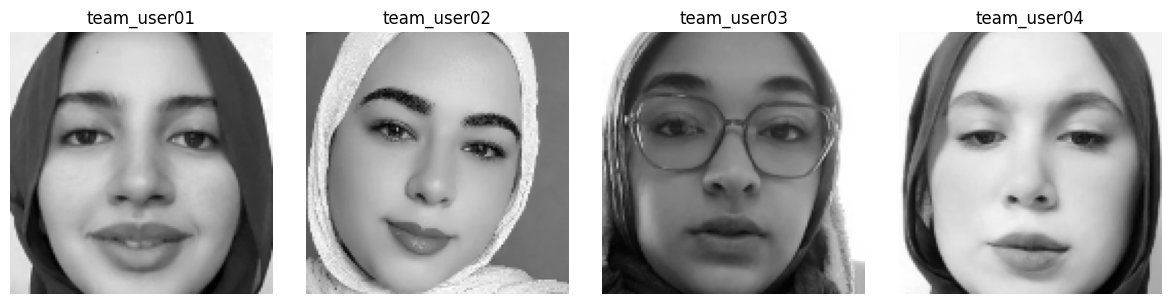

In [ ]:
processed = ROOT / "processed"
processed.mkdir(exist_ok=True)
image_paths, audio_paths, durations = [], [], []
for row in team_df.itertuples():
    folder = processed / row.user_id / row.split
    folder.mkdir(parents=True, exist_ok=True)
    image_path = folder / f"{row.recording_id}.jpg"
    audio_path = folder / f"{row.recording_id}.wav"
    durations.append(prepare_video(row.video_path, image_path, audio_path))
    image_paths.append(str(image_path))
    audio_paths.append(str(audio_path))
team_df["image_path"] = image_paths
team_df["audio_path"] = audio_paths
team_df["duration_s"] = durations
team_df.to_csv(OUT / "team_manifest.csv", index=False)

fig, axes = plt.subplots(1, len(USERS), figsize=(3 * len(USERS), 3))
for ax, user in zip(np.ravel(axes), USERS):
    row = team_df[team_df.user_id == user].iloc[0]
    ax.imshow(preprocess_face(row.image_path), cmap="gray")
    ax.set_title(user)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Face HOG/LBP Features and Two ML Models

In [ ]:
def image_features(image, method):
    if method == "HOG":
        return hog(image, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2))
    if method == "LBP":
        lbp = local_binary_pattern(image, 8, 1, method="uniform")
        features = []
        for row in range(0, 128, 32):
            for col in range(0, 128, 32):
                counts = np.bincount(lbp[row:row + 32, col:col + 32].astype(int).ravel(), minlength=10).astype(float)
                features.extend(counts / counts.sum())
        return np.array(features)
    raise ValueError("Choose HOG or LBP.")

face_images = [preprocess_face(path) for path in team_df.image_path]
face_X = {
    method: np.stack([image_features(image, method) for image in face_images])
    for method in ["HOG", "LBP"]
}
face_bundle, face_table, face_candidates = train_candidates(
    face_X, team_df.user_id, team_df.split, "Face"
)
display(face_table)

,Modality,Model,Accuracy,Precision,Recall,F1
0,Face,HOG_SVM,1.000000,1.000000,1.000000,1.000000
1,Face,HOG_RandomForest,1.000000,1.000000,1.000000,1.000000
2,Face,LBP_RandomForest,0.939394,0.954545,0.944444,0.943750
3,Face,LBP_SVM,0.909091,0.937500,0.916667,0.914286


# Part Two — Voice Verification and Commands
## 6. MFCC, ZCR, RMS and Two Voice Models

In [ ]:
def voice_features(audio_path):
    signal, sr = librosa.load(str(audio_path), sr=16000, mono=True)
    signal, _ = librosa.effects.trim(signal, top_db=25)
    if len(signal) < 512:
        raise ValueError(f"Speech is too short: {audio_path}")
    mfcc = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=13)
    zcr = librosa.feature.zero_crossing_rate(y=signal)
    rms = librosa.feature.rms(y=signal)
    return np.r_[mfcc.mean(axis=1), mfcc.std(axis=1),
                 zcr.mean(axis=1), zcr.std(axis=1),
                 rms.mean(axis=1), rms.std(axis=1)]

voice_X = {"MFCC_ZCR_RMS": np.stack([voice_features(path) for path in team_df.audio_path])}
voice_bundle, voice_table, voice_candidates = train_candidates(
    voice_X, team_df.user_id, team_df.split, "Voice"
)
display(voice_table)

,Modality,Model,Accuracy,Precision,Recall,F1
0,Voice,MFCC_ZCR_RMS_SVM,0.909091,0.9375,0.916667,0.914286
1,Voice,MFCC_ZCR_RMS_KNN,0.818182,0.9000,0.819444,0.828638


## 7. Isolated Commands and User Permissions

In [ ]:
command_bundle, command_table, command_candidates = train_candidates(
    voice_X, team_df.command, team_df.split, "Command"
)
permission_options = [
    ["open", "close", "status"],
    ["status"],
    ["open", "status"],
    ["close", "status"]
]

permissions = {
    user: permission_options[index]
    for index, user in enumerate(USERS)
}
command_bundle["minimum_score"] = COMMAND_MIN_SCORE
with (OUT / "permissions.json").open("w") as file:
    json.dump(permissions, file, indent=2)
display(command_table)
display(pd.DataFrame([
    {"User": user, "AllowedCommands": ", ".join(allowed)}
    for user, allowed in permissions.items()
]))

,Modality,Model,Accuracy,Precision,Recall,F1
0,Command,MFCC_ZCR_RMS_SVM,0.848485,0.867725,0.848485,0.850794
1,Command,MFCC_ZCR_RMS_RandomForest,0.848485,0.858201,0.848485,0.845714


,User,AllowedCommands
0,team_user01,"open, close, status"
1,team_user02,status
2,team_user03,"open, status"
3,team_user04,"close, status"


In [ ]:
val_mask = team_df["split"].eq("val").to_numpy()
model = command_bundle["model"]
features = voice_X[command_bundle["feature"]][val_mask]

predictions = model.predict(features)
probabilities = model.predict_proba(features)
classes = list(model.classes_)

scores = [
    probabilities[index, classes.index(command)]
    for index, command in enumerate(predictions)
]

command_check = team_df.loc[
    val_mask, ["user_id", "command"]
].reset_index(drop=True)

command_check["prediction"] = predictions
command_check["score"] = scores
command_check["correct"] = (
    command_check["command"] == command_check["prediction"]
)
command_check["passes_threshold"] = (
    command_check["score"] >= command_bundle["minimum_score"]
)

display(command_check)

,user_id,command,prediction,score,correct,passes_threshold
0,team_user01,close,status,0.930684,False,True
1,team_user01,close,close,0.981630,True,True
2,team_user01,close,close,0.725580,True,True
3,team_user01,open,open,0.536595,True,True
4,team_user01,open,open,0.644584,True,True
5,team_user01,open,open,0.892162,True,True
6,team_user01,status,close,0.949687,False,True
7,team_user01,status,status,0.872842,True,True
8,team_user01,status,status,0.724257,True,True
9,team_user02,close,close,0.854151,True,True


# Part Three — Fingerprint Verification and Dataset Organization
## 8. Simulated Fingerprint Mapping and Separate Impressions

In [ ]:
fp_folders = sorted(
    path for path in (INPUT / "fingerprints").rglob("*")
    if path.is_dir() and path.name.lower() == "db1_a"
)
if not fp_folders and fp_archives[0].stem.lower() == "db1_a":
    fp_folders = [INPUT / "fingerprints"]
assert len(fp_folders) == 1, "Expected one Db1_a folder in the fingerprint ZIP."
FP_DATA = fp_folders[0]
fp_rows = []
for path in sorted(FP_DATA.iterdir()):
    if path.suffix.lower() not in {".tif", ".tiff"}:
        continue
    finger, impression = map(int, path.stem.split("_"))
    fp_rows.append({"finger_id": finger, "sample_id": impression, "fingerprint_path": str(path)})
fp_df = pd.DataFrame(fp_rows)
assert not fp_df.empty, "No fingerprint images found."
assert not fp_df.duplicated(["finger_id", "sample_id"]).any()
counts = fp_df.groupby("finger_id").size()
fingers = sorted(counts[counts == 8].index)[:EXPECTED_USERS]
assert len(fingers) == EXPECTED_USERS, "Need four different fingers with eight impressions each."
fp_mapping = pd.DataFrame({"user_id": USERS, "finger_id": fingers})
fp_df = fp_df.merge(fp_mapping, on="finger_id", how="inner", validate="many_to_one")
fp_df = fp_df.groupby("user_id").sample(frac=1, random_state=SEED).reset_index(drop=True)
fp_df["split"] = fp_df.groupby("user_id").cumcount().map(
    dict(enumerate(["train"] * 4 + ["val"] * 2 + ["test"] * 2))
)
fp_df["sha256"] = [hashlib.sha256(Path(path).read_bytes()).hexdigest() for path in fp_df.fingerprint_path]
assert not fp_df.sha256.duplicated().any(), "Duplicate fingerprint images found."


## 8.2 Link Fingerprints to Team IDs

In [ ]:

paired_fingerprints = []
fp_positions = {}
for row in team_df.itertuples():
    candidates = fp_df[(fp_df.user_id == row.user_id) & (fp_df.split == row.split)].sort_values("sample_id")
    key = (row.user_id, row.split)
    position = fp_positions.get(key, 0)
    paired_fingerprints.append(candidates.iloc[position % len(candidates)].fingerprint_path)
    fp_positions[key] = position + 1
team_df["fingerprint_path"] = paired_fingerprints
fp_mapping.to_csv(OUT / "fingerprint_mapping.csv", index=False)
fp_df.to_csv(OUT / "fingerprint_manifest.csv", index=False)
team_df.to_csv(OUT / "team_manifest.csv", index=False)
display(fp_mapping)

,user_id,finger_id
0,team_user01,1
1,team_user02,10
2,team_user03,11
3,team_user04,100


## 9. Fingerprint Features and Two ML Models

In [ ]:
def preprocess_fingerprint(image_path):
    with Image.open(image_path) as source:
        image = source.convert("L")
    mask = np.array(image) < 200
    rows = np.flatnonzero(mask.mean(axis=1) > 0.05)
    cols = np.flatnonzero(mask.mean(axis=0) > 0.05)
    if len(rows) and len(cols):
        image = image.crop((max(0, int(cols[0]) - 5), max(0, int(rows[0]) - 5),
                            min(image.width, int(cols[-1]) + 6), min(image.height, int(rows[-1]) + 6)))
    image = ImageOps.pad(ImageOps.autocontrast(image), (128, 128),
                         method=Image.Resampling.LANCZOS, color=255)
    return np.array(image)

fp_images = [preprocess_fingerprint(path) for path in fp_df.fingerprint_path]
fp_X = {
    method: np.stack([image_features(image, method) for image in fp_images])
    for method in ["HOG", "LBP"]
}
fingerprint_bundle, fingerprint_table, fingerprint_candidates = train_candidates(
    fp_X, fp_df.user_id, fp_df.split, "Fingerprint"
)
fp_lookup = {path: index for index, path in enumerate(fp_df.fingerprint_path)}
team_fp_indices = [fp_lookup[path] for path in team_df.fingerprint_path]
team_fp_X = fp_X[fingerprint_bundle["feature"]][team_fp_indices]
display(fingerprint_table)

,Modality,Model,Accuracy,Precision,Recall,F1
0,Fingerprint,LBP_RandomForest,0.750,0.833333,0.750,0.733333
1,Fingerprint,HOG_RandomForest,0.625,0.500000,0.625,0.550000
2,Fingerprint,HOG_SVM,0.625,0.541667,0.625,0.533333
3,Fingerprint,LBP_SVM,0.625,0.458333,0.625,0.525000


# Part Four — Face/Voice Fusion and Three-Modality Comparison

Face and voice features are combined using Early Fusion for identity verification.

A separate experiment combines face, voice and fingerprint features. Fingerprints are linked to team identities through a simulated mapping and do not control command permissions.



Exact duplicate videos were removed, and User04 recordings were reassigned to train, validation and test. Results are a re-evaluation of previously inspected recordings.

Fingerprint samples are reused across paired videos within the same split, which limits the independence of the three-modality evaluation.

In [ ]:
# Keep the original face + voice baseline and add the fingerprint variant.
face_voice_features = np.column_stack([
    face_X["HOG"], face_X["LBP"], voice_X["MFCC_ZCR_RMS"]
])
fusion_X = {"HOG_LBP_Voice": face_voice_features}
triple_fusion_X = {"HOG_LBP_Voice_Fingerprint": np.column_stack([
    face_voice_features, team_fp_X
])}

fusion_bundle, fusion_table, _ = train_candidates(
    fusion_X, team_df.user_id, team_df.split, "Fusion"
)
triple_fusion_bundle, triple_fusion_table, _ = train_candidates(
    triple_fusion_X, team_df.user_id, team_df.split, "Fusion3"
)

BUNDLES = {
    "Face": face_bundle, "Voice": voice_bundle,
    "Fusion": fusion_bundle, "Fusion3": triple_fusion_bundle,
    "Fingerprint": fingerprint_bundle, "Command": command_bundle
}
validation_tables = pd.concat([
    face_table, voice_table, fingerprint_table,
    fusion_table, triple_fusion_table, command_table
], ignore_index=True)
validation_tables.to_csv(OUT / "validation_experiments.csv", index=False)
display(pd.concat([fusion_table, triple_fusion_table], ignore_index=True))
print("Face + Voice features:", face_voice_features.shape[1])
print("Face + Voice + Fingerprint features:", triple_fusion_X["HOG_LBP_Voice_Fingerprint"].shape[1])


,Modality,Model,Accuracy,Precision,Recall,F1
0,Fusion,HOG_LBP_Voice_SVM,1.0,1.0,1.0,1.0
1,Fusion,HOG_LBP_Voice_RandomForest,1.0,1.0,1.0,1.0
2,Fusion3,HOG_LBP_Voice_Fingerprint_SVM,1.0,1.0,1.0,1.0
3,Fusion3,HOG_LBP_Voice_Fingerprint_RandomForest,1.0,1.0,1.0,1.0


Face + Voice features: 8290
Face + Voice + Fingerprint features: 8450


## 11. Evaluate All Methods (including Three-Modality Fusion)

The three-modality experiment uses simulated fingerprint-to-team mapping. Compare its performance with the original Face+Voice baseline, but note that repeated fingerprint impressions reduce the effective test sample size.

In [ ]:
team_test = team_df.split.to_numpy() == "test"
fp_test = fp_df.split.to_numpy() == "test"
score_sources = {
    "Face": (face_X[face_bundle["feature"]][team_test], team_df.loc[team_test, "user_id"].to_numpy()),
    "Voice": (voice_X[voice_bundle["feature"]][team_test], team_df.loc[team_test, "user_id"].to_numpy()),
    "Fusion": (fusion_X["HOG_LBP_Voice"][team_test], team_df.loc[team_test, "user_id"].to_numpy()),
    "Fusion3": (triple_fusion_X["HOG_LBP_Voice_Fingerprint"][team_test], team_df.loc[team_test, "user_id"].to_numpy()),
    "Fingerprint": (fp_X[fingerprint_bundle["feature"]][fp_test], fp_df.loc[fp_test, "user_id"].to_numpy())
}
verification_rows = []
confusions = {}
team_stage_predictions = []

for name, (X, labels) in score_sources.items():
    bundle = BUNDLES[name]
    scores = bundle["model"].predict_proba(X)
    truth, values = claim_scores(scores, labels, bundle["model"].classes_)
    prediction = (values >= bundle["threshold"]).astype(int)
    verification_rows.append({"Method": name, **verification_metrics(truth, prediction)})
    confusions[name] = confusion_matrix(truth, prediction, labels=[0, 1])


## 11.2 Compare the Operational Hierarchy with an Experimental Fingerprint-Gated Hierarchy

`Hierarchy` uses Face, Voice and Face+Voice Fusion only; this is the command-authorization path. `Hierarchy_FP_Experiment` additionally gates on Fingerprint and Fusion3 **for comparison only**. It must not affect allowed commands.

In [ ]:
stage_scores = {}
for name, X in [
    ("Face", face_X[face_bundle["feature"]][team_test]),
    ("Voice", voice_X[voice_bundle["feature"]][team_test]),
    ("Fusion", fusion_X["HOG_LBP_Voice"][team_test]),
    ("Fingerprint", team_fp_X[team_test]),
    ("Fusion3", triple_fusion_X["HOG_LBP_Voice_Fingerprint"][team_test])
]:
    bundle = BUNDLES[name]
    order = [list(bundle["model"].classes_).index(user) for user in USERS]
    scores = bundle["model"].predict_proba(X)[:, order]
    stage_scores[name] = scores >= bundle["threshold"]

true_users = team_df.loc[team_test, "user_id"].to_numpy()
hierarchy_truth = (true_users[:, None] == np.array(USERS)[None, :]).astype(int).ravel()

hierarchies = {
    "Hierarchy": ["Face", "Voice", "Fusion"],
    "Hierarchy_FP_Experiment": ["Face", "Voice", "Fusion", "Fingerprint", "Fusion3"]
}
for name, stages in hierarchies.items():
    prediction = np.logical_and.reduce([stage_scores[stage] for stage in stages])
    prediction = prediction.astype(int).ravel()
    verification_rows.append({"Method": name, **verification_metrics(hierarchy_truth, prediction)})
    confusions[name] = confusion_matrix(hierarchy_truth, prediction, labels=[0, 1])

verification_results = pd.DataFrame(verification_rows)
verification_results.to_csv(OUT / "verification_test_results.csv", index=False)
display(verification_results)

,Method,Accuracy,BalancedAccuracy,Precision,Recall,F1,FAR,FRR
0,Face,1.000000,1.000000,1.000000,1.000000,1.000000,0.00000,0.000000
1,Voice,0.964286,0.952381,0.928571,0.928571,0.928571,0.02381,0.071429
2,Fusion,1.000000,1.000000,1.000000,1.000000,1.000000,0.00000,0.000000
3,Fusion3,1.000000,1.000000,1.000000,1.000000,1.000000,0.00000,0.000000
4,Fingerprint,0.843750,0.812500,0.666667,0.750000,0.705882,0.12500,0.250000
5,Hierarchy,0.982143,0.964286,1.000000,0.928571,0.962963,0.00000,0.071429
6,Hierarchy_FP_Experiment,0.910714,0.821429,1.000000,0.642857,0.782609,0.00000,0.357143


## 11.3 Confusion Matrices and Command Evaluation

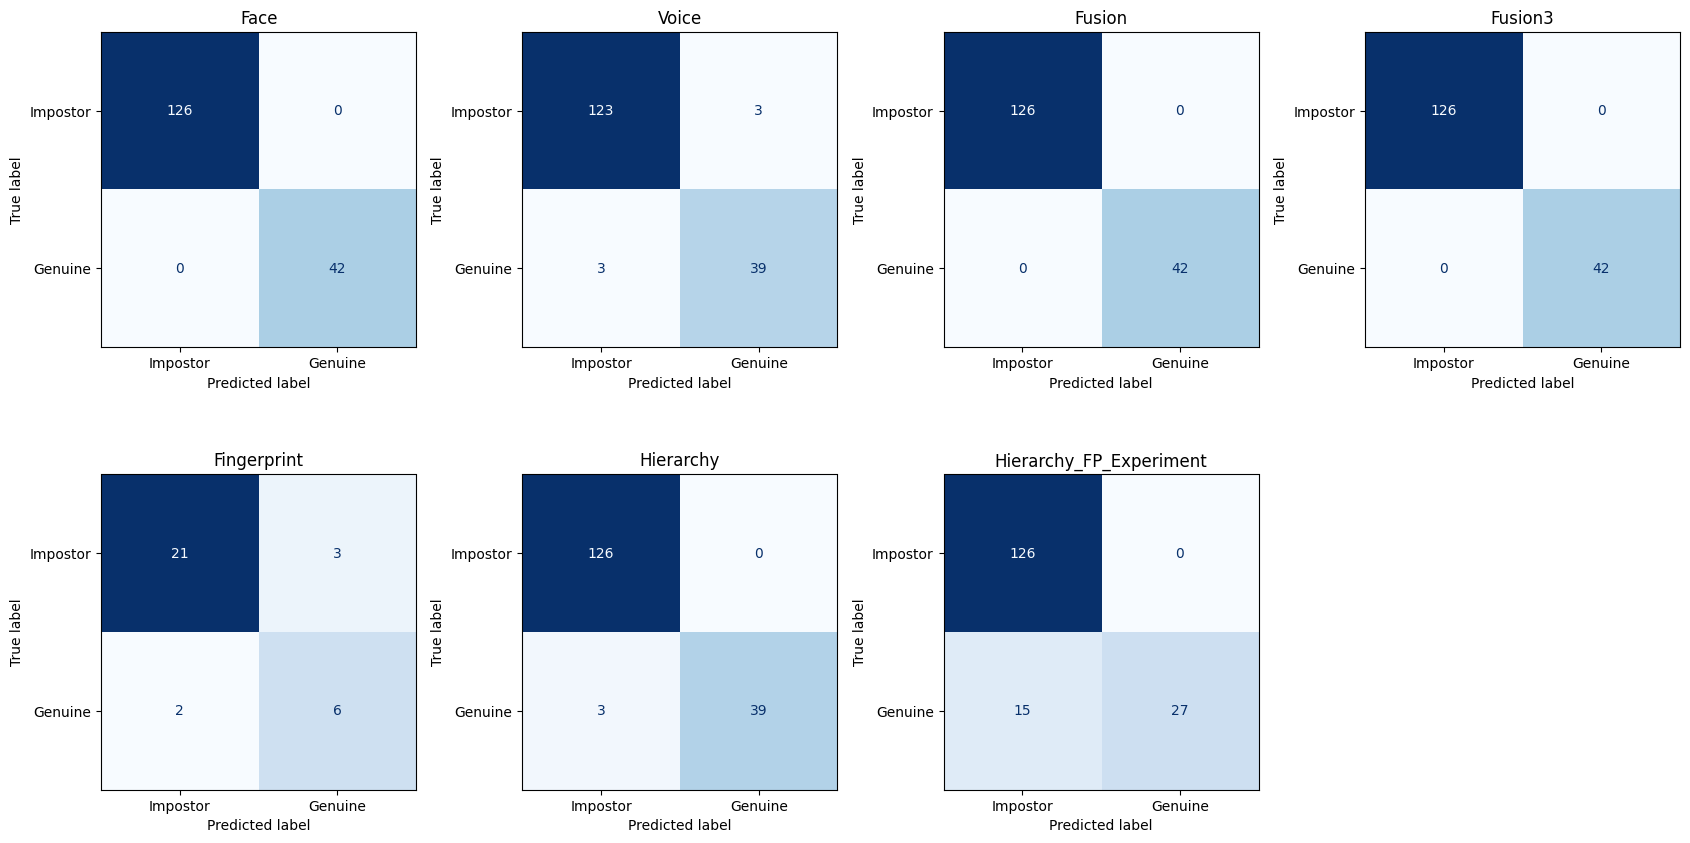

,Accuracy,Precision,Recall,F1
0,0.880952,0.883883,0.880952,0.881682


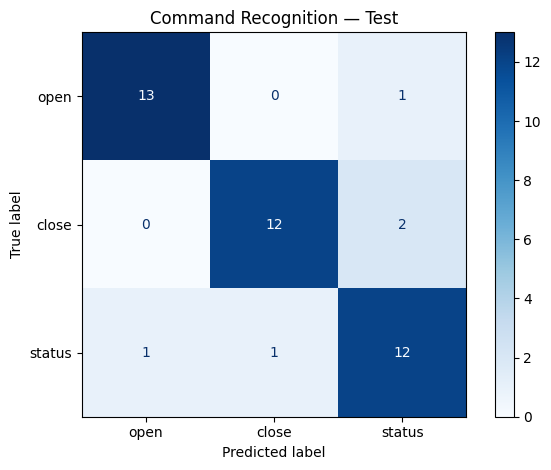

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(17, 9))
for ax, (name, matrix) in zip(axes.flat, confusions.items()):
    ConfusionMatrixDisplay(matrix, display_labels=["Impostor", "Genuine"]).plot(
        ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(name)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.savefig(OUT / "verification_confusion_matrices.png", dpi=160)
plt.show()
command_test_X = voice_X["MFCC_ZCR_RMS"][team_test]
command_test_y = team_df.loc[team_test, "command"].to_numpy()
command_test_pred = command_bundle["model"].predict(command_test_X)
command_results = pd.DataFrame([classification_metrics(command_test_y, command_test_pred)])
command_results.to_csv(OUT / "command_test_results.csv", index=False)
display(command_results)
ConfusionMatrixDisplay.from_predictions(
    command_test_y, command_test_pred, labels=COMMANDS, cmap="Blues"
)
plt.title("Command Recognition — Test")
plt.tight_layout()
plt.savefig(OUT / "command_confusion_matrix.png", dpi=160)
plt.show()

In [ ]:
mask = team_df["split"].eq("test").to_numpy()
prediction = command_bundle["model"].predict(
    voice_X[command_bundle["feature"]][mask]
)
display(pd.DataFrame([classification_metrics(
    team_df.loc[mask, "command"].to_numpy(),
    prediction
)]))

,Accuracy,Precision,Recall,F1
0,0.880952,0.883883,0.880952,0.881682


## 12. Save Models, Manifests and Evaluation Notes

In [ ]:
joblib.dump(BUNDLES, OUT / "models.pkl")
for name, bundle in BUNDLES.items():
    joblib.dump(bundle, OUT / f"{name.lower()}_model.pkl")
feature_keys = team_df[["user_id", "recording_id", "command", "split"]].reset_index(drop=True)
face_csv = pd.concat([
    feature_keys,
    pd.DataFrame(face_X["HOG"]).add_prefix("hog_"),
    pd.DataFrame(face_X["LBP"]).add_prefix("lbp_")
], axis=1)
voice_csv = pd.concat([
    feature_keys,
    pd.DataFrame(voice_X["MFCC_ZCR_RMS"]).add_prefix("voice_")
], axis=1)
face_csv.to_csv(OUT / "face_features.csv", index=False)
voice_csv.to_csv(OUT / "voice_features.csv", index=False)
face_csv.merge(voice_csv, on=["user_id", "recording_id", "command", "split"], validate="one_to_one").to_csv(
    OUT / "early_fusion_ready.csv", index=False
)
with (OUT / "settings.json").open("w") as file:
    json.dump({"users": USERS, "commands": COMMANDS,
               "use_fingerprint": False, "fingerprint_mode": "experimental_only",
               "operational_stages": ["Face", "Voice", "Fusion"], "seed": SEED}, file, indent=2)

# Save simulated 3-modality feature matrix with the paired recording keys.
pd.concat([
    feature_keys,
    pd.DataFrame(triple_fusion_X["HOG_LBP_Voice_Fingerprint"]).add_prefix("fusion3_")
], axis=1).to_csv(OUT / "three_modality_fusion_features.csv", index=False)


## 12.2 Save Dataset Manifests

In [ ]:

manifest_parts = []
for modality, path_column in [("face", "image_path"), ("voice", "audio_path")]:
    part = team_df[["user_id", "recording_id", "command", "split", path_column]].copy()
    part = part.rename(columns={"recording_id": "sample_id", path_column: "path"})
    part["modality"] = modality
    part["source_id"] = part.user_id
    manifest_parts.append(part)
part = fp_df[["user_id", "finger_id", "sample_id", "split", "fingerprint_path"]].copy()
part["source_id"] = part.finger_id.astype(str)
part["sample_id"] = part.finger_id.astype(str) + "_" + part.sample_id.astype(str)
part["modality"] = "fingerprint"
part = part.rename(columns={"fingerprint_path": "path"})
manifest_parts.append(part)
pd.concat(manifest_parts, ignore_index=True)[
    ["user_id", "modality", "sample_id", "source_id", "command", "split", "path"]
].to_csv(OUT / "dataset_manifest.csv", index=False)
np.savez_compressed(
    OUT / "extracted_features.npz", face_hog=face_X["HOG"], face_lbp=face_X["LBP"],
    voice=voice_X["MFCC_ZCR_RMS"], fingerprint_hog=fp_X["HOG"], fingerprint_lbp=fp_X["LBP"]
)


## 12.3 Save Metric Definitions and Notes

In [ ]:
metric_definitions = pd.DataFrame([
    ["Accuracy", "Correct decisions / all claims; affected by claim imbalance."],
    ["BalancedAccuracy", "Average genuine acceptance and impostor rejection; balances both claim types."],
    ["Precision", "Genuine claims / all accepted claims."],
    ["Recall", "Accepted genuine claims / all genuine claims."],
    ["F1", "Harmonic mean of genuine-claim precision and recall."],
    ["FAR", "Accepted impostor claims / all impostor claims; security error."],
    ["FRR", "Rejected genuine claims / all genuine claims; usability error."]
], columns=["Metric", "Meaning"])
metric_definitions.to_csv(OUT / "metric_definitions.csv", index=False)
display(metric_definitions)
(OUT / "evaluation_notes.txt").write_text(
    "Custom face/voice data belongs to the recorded team members.\n"
    "Fingerprint pairing is simulated across different real identities.\n"
    "All modalities of a video stay in its supplied train/val/test folder.\n"
    "Scalers, models and fingerprint references use training data only.\n"
    "Model selection and verification thresholds use validation only.\n"
    "Test results must not be used for further tuning.\n"
    "Each test sample has 1 genuine and N-1 other-enrolled-user impostor claims.\n"
    "Fingerprint-only evaluation uses independent fingerprint impressions.\n"
    "The experimental fingerprint hierarchy cycles same-split fingerprint samples when videos outnumber impressions.\n"
    "Operational command authorization uses Face, Voice, and Face+Voice Fusion only.\n"
    "Fingerprint-only and Fusion3 are experimental metrics, not real-user biometric proof.\n"
    "Small and uneven validation/test splits and repeated video recordings limit reliability.\n"
    "Short isolated words provide limited speaker information.\n"
    "Unknown words, unknown-person biometric rejection, replay resistance and other locations are not benchmarked.\n"
    "The gate rejects unknown claimed IDs; other enrolled users provide impostor trials.\n"
    "Camera/microphone recording requires browser permission and a manual live-demo run.\n",
    encoding="utf-8"
)

,Metric,Meaning
0,Accuracy,Correct decisions / all claims; affected by cl...
1,BalancedAccuracy,Average genuine acceptance and impostor reject...
2,Precision,Genuine claims / all accepted claims.
3,Recall,Accepted genuine claims / all genuine claims.
4,F1,Harmonic mean of genuine-claim precision and r...
5,FAR,Accepted impostor claims / all impostor claims...
6,FRR,Rejected genuine claims / all genuine claims; ...


1229

## 13. Linked Identity Verification, Commands and Permissions

In [ ]:
@lru_cache(maxsize=4)
def load_assets(folder):
    folder = Path(folder)
    bundles = joblib.load(folder / "models.pkl")
    permissions = json.loads((folder / "permissions.json").read_text())
    settings = json.loads((folder / "settings.json").read_text())
    return bundles, permissions, settings
def verify_features(features, claimed_id, bundle):
    claimed_id = str(claimed_id)
    model = bundle["model"]
    classes = list(model.classes_)
    if claimed_id not in classes:
        return {"verified": False, "score": 0.0, "reason": "Unknown ID"}
    score = float(model.predict_proba(np.asarray(features).reshape(1, -1))[0, classes.index(claimed_id)])
    return {"verified": bool(score >= bundle["threshold"]),
            "score": score, "threshold": float(bundle["threshold"])}
def verify_face(image_path, claimed_id, folder):
    bundles, _, _ = load_assets(str(Path(folder).resolve()))
    try:
        image = preprocess_face(image_path)
    except ValueError as error:
        return {"verified": False, "score": 0.0, "reason": str(error)}
    features = image_features(image, bundles["Face"]["feature"])
    return verify_features(features, claimed_id, bundles["Face"])
def verify_voice(audio_path, claimed_id, folder):
    bundles, _, _ = load_assets(str(Path(folder).resolve()))
    try:
        features = voice_features(audio_path)
    except (ValueError, RuntimeError) as error:
        return {"verified": False, "score": 0.0, "reason": str(error)}
    return verify_features(features, claimed_id, bundles["Voice"])
def verify_fingerprint(image_path, claimed_id, folder):
    bundles, _, _ = load_assets(str(Path(folder).resolve()))
    image = preprocess_fingerprint(image_path)
    features = image_features(image, bundles["Fingerprint"]["feature"])
    return verify_features(features, claimed_id, bundles["Fingerprint"])


## 13.2 Experimental Three-Modality Verification (Bonus 4)

Use a supplied fingerprint image for an **independent evaluation result**. It is not required by the operational Face/Voice hierarchy and is never silently treated as proof of the real speaker’s fingerprint.

In [ ]:
def verify_fusion3(image_path, audio_path, fingerprint_path, claimed_id, folder):
    """Verify a claimed ID using concatenated face, voice, and fingerprint features."""
    bundles, _, _ = load_assets(str(Path(folder).resolve()))
    image = preprocess_face(image_path)
    fingerprint = preprocess_fingerprint(fingerprint_path)
    combined = np.r_[image_features(image, "HOG"), image_features(image, "LBP"),
                     voice_features(audio_path),
                     image_features(fingerprint, bundles["Fingerprint"]["feature"])]
    return verify_features(combined, claimed_id, bundles["Fusion3"])
def evaluate_fingerprint_bonus(image_path, audio_path, fingerprint_path, claimed_id, folder):
    """Run independent simulated fingerprint checks without authorizing any action."""
    fingerprint = verify_fingerprint(fingerprint_path, claimed_id, folder)
    fusion3 = verify_fusion3(image_path, audio_path, fingerprint_path, claimed_id, folder)
    return {"experimental_only": True, "user_id": str(claimed_id),
            "Fingerprint": fingerprint, "Fusion3": fusion3,
            "experimental_combined_pass": bool(fingerprint["verified"] and fusion3["verified"])}


## 13.3 Operational Hierarchy — Face → Voice → Face+Voice Fusion

This is the only identity gate for the protected-command workflow. The optional `fingerprint_path` argument is accepted for compatibility but intentionally has no effect on authorization. The fingerprint bonus is reported separately.

In [ ]:
def hierarchical_verify(image_path, audio_path, claimed_id, folder, fingerprint_path=None):
    """Main authorization identity gate: face, voice, and face+voice fusion only.

    fingerprint_path is accepted for backward compatibility but is ignored.
    Fingerprints are simulated Bonus 4 data and cannot deny/allow real-user actions.
    """
    bundles, _, settings = load_assets(str(Path(folder).resolve()))
    claimed_id = str(claimed_id)
    result = {"verified": False, "user_id": claimed_id, "stages": {}}
    if claimed_id not in settings["users"]:
        result["reason"] = "Unknown ID"
        return result
    face_result = verify_face(image_path, claimed_id, folder)
    result["stages"]["Face"] = face_result
    if not face_result["verified"]:
        result["reason"] = "Face verification failed"
        return result
    voice_result = verify_voice(audio_path, claimed_id, folder)
    result["stages"]["Voice"] = voice_result
    if not voice_result["verified"]:
        result["reason"] = "Voice verification failed"
        return result
    image = preprocess_face(image_path)
    features = np.r_[image_features(image, "HOG"), image_features(image, "LBP"), voice_features(audio_path)]
    fusion_result = verify_features(features, claimed_id, bundles["Fusion"])
    result["stages"]["Fusion"] = fusion_result
    if not fusion_result["verified"]:
        result["reason"] = "Face/voice fusion verification failed"
        return result
    result["verified"] = True
    result["reason"] = "Identity verified by face and voice"
    return result

## 13.4 Commands and Permissions — Authorized Only by the Face/Voice Hierarchy

In [ ]:
def recognize_command(audio_path, folder):
    bundles, _, _ = load_assets(str(Path(folder).resolve()))
    bundle = bundles["Command"]
    features = voice_features(audio_path).reshape(1, -1)
    command = str(bundle["model"].predict(features)[0])
    scores = bundle["model"].predict_proba(features)[0]
    index = list(bundle["model"].classes_).index(command)
    return {"command": command, "score": float(scores[index]),
            "recognized": bool(scores[index] >= bundle["minimum_score"])}
def check_permission(user_id, command, folder):
    _, permissions, _ = load_assets(str(Path(folder).resolve()))
    return command in permissions.get(str(user_id), [])
def protected_command(image_path, audio_path, claimed_id, folder, fingerprint_path=None, state="closed"):
    """A fingerprint input is ignored for operational command authorization."""
    authentication = hierarchical_verify(image_path, audio_path, claimed_id, folder, fingerprint_path)
    result = {"verified": authentication["verified"], "user_id": str(claimed_id),
              "command": None, "allowed": False, "state": state,
              "reason": authentication["reason"]}
    if not authentication["verified"]:
        return result
    command = recognize_command(audio_path, folder)
    result["command"] = command["command"]
    if not command["recognized"]:
        result["reason"] = "Uncertain command"
        return result
    if not check_permission(claimed_id, command["command"], folder):
        result["reason"] = "No permission"
        return result
    result["allowed"] = True
    result["state"] = {"open": "open", "close": "closed", "status": state}[command["command"]]
    result["reason"] = "Authorized simulated action"
    return result

## 14. Integrated Protected-Command Test (Fingerprint Does Not Block Commands)

In [ ]:
linked_rows = []
for row in team_df[team_df.split == "test"].itertuples():
    for claimed_id in USERS + ["unknown_user"]:
        result = protected_command(
            row.image_path, row.audio_path, claimed_id, OUT,
            fingerprint_path=None  # Operational identity is Face+Voice only
        )
        identity_correct = claimed_id == row.user_id
        expected_allowed = identity_correct and row.command in permissions.get(claimed_id, [])
        linked_rows.append({
            "ActualUser": row.user_id, "ClaimedUser": claimed_id,
            "TrueCommand": row.command, "PredictedCommand": result["command"],
            "Verified": result["verified"], "ExpectedAllowed": expected_allowed,
            "Allowed": result["allowed"], "Reason": result["reason"]
        })
linked_results = pd.DataFrame(linked_rows)
linked_results.to_csv(OUT / "linked_command_test.csv", index=False)
assert not linked_results.loc[~linked_results.Verified, "Allowed"].any()
assert not linked_results.loc[linked_results.ClaimedUser == "unknown_user", "Allowed"].any()
linked_summary = pd.DataFrame([{
    "PermissionDecisionAccuracy": accuracy_score(linked_results.ExpectedAllowed, linked_results.Allowed),
    "UnauthorizedAccepts": int((linked_results.Allowed & ~linked_results.ExpectedAllowed).sum()),
    "AuthorizedRejects": int((~linked_results.Allowed & linked_results.ExpectedAllowed).sum()),
    "AuthorizedClaims": int(linked_results.ExpectedAllowed.sum())
}])
linked_summary.to_csv(OUT / "linked_command_summary.csv", index=False)
display(linked_summary)
display(linked_results.groupby(["ActualUser", "ClaimedUser", "Reason"], as_index=False).size().head(16))

,PermissionDecisionAccuracy,UnauthorizedAccepts,AuthorizedRejects,AuthorizedClaims
0,0.97619,0,5,28


,ActualUser,ClaimedUser,Reason,size
0,team_user01,team_user01,Authorized simulated action,9
1,team_user01,team_user01,Uncertain command,1
2,team_user01,team_user01,Voice verification failed,2
3,team_user01,team_user02,Face verification failed,12
4,team_user01,team_user03,Face verification failed,12
5,team_user01,team_user04,Face verification failed,12
6,team_user01,unknown_user,Unknown ID,12
7,team_user02,team_user01,Face verification failed,12
8,team_user02,team_user02,Authorized simulated action,3
9,team_user02,team_user02,No permission,8


In [ ]:
correct_command = (
    linked_results["TrueCommand"]
    == linked_results["PredictedCommand"]
)
successful = (
    linked_results["ExpectedAllowed"]
    & linked_results["Allowed"]
    & correct_command
)
display(pd.DataFrame([{
    "AuthorizedRequests": int(
        linked_results["ExpectedAllowed"].sum()
    ),
    "CorrectExecutions": int(successful.sum()),
    "WrongCommandExecutions": int(
        (linked_results["Allowed"] & ~correct_command).sum()
    )
}]))

,AuthorizedRequests,CorrectExecutions,WrongCommandExecutions
0,28,21,2


## 15. Export the Pipeline and Final Results

In [ ]:
execution_summary = pd.DataFrame([{
    "AuthorizedRequests": int(linked_results["ExpectedAllowed"].sum()),
    "CorrectExecutions": int(successful.sum()),
    "WrongCommandExecutions": int(
        (linked_results["Allowed"] & ~correct_command).sum()
    )
}])
execution_summary.to_csv(
    OUT / "command_execution_summary.csv", index=False
)
module_imports = """from pathlib import Path
from functools import lru_cache
import json
import cv2
import librosa
import joblib
import numpy as np
from PIL import Image, ImageOps
from skimage.feature import hog, local_binary_pattern

face_detector = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)
"""
export_functions = [
    preprocess_face, image_features, voice_features,
    preprocess_fingerprint, load_assets, verify_features,
    verify_face, verify_voice, verify_fingerprint,
    verify_fusion3, evaluate_fingerprint_bonus,
    hierarchical_verify, recognize_command,
    check_permission, protected_command
]
module_source = module_imports + "\n\n" + "\n\n".join(
    inspect.getsource(function) for function in export_functions
)
(OUT / "team_pipeline.py").write_text(
    module_source, encoding="utf-8"
);

## 15.2 Save Requirements and Download the Package

In [ ]:
packages = [
    "numpy", "pandas", "matplotlib", "pillow",
    "scikit-learn", "scikit-image",
    "opencv-python-headless", "librosa", "soundfile", "joblib"
]
(OUT / "requirements.txt").write_text(
    "\n".join(
        f"{package}=={version(package)}"
        for package in packages
    ) + "\n",
    encoding="utf-8"
)
(OUT / "usage.txt").write_text(
    "from team_pipeline import protected_command, evaluate_fingerprint_bonus\n"
    "result = protected_command(image_path, audio_path, claimed_id, model_folder)\n"
    "bonus = evaluate_fingerprint_bonus(image_path, audio_path, fingerprint_path, claimed_id, model_folder)\n"
    "Main flow: Face -> Voice -> Face/Voice Fusion -> Command -> Permission.\n"
    "Open and close actions are simulated state changes.\n"
    "Fingerprint ownership is simulated; fingerprint and Fusion3 are evaluated separately.\n"
    "Paths in manifests refer to the Colab environment.\n"
    "Keep the executed notebook and source datasets separately.\n",
    encoding="utf-8"
)
(OUT / "evaluation_notes.txt").write_text(
    "Exact duplicate video files were removed before training.\n"
    "User04 unique videos were reassigned to train, validation and test.\n"
    "All modalities follow the split column in the saved manifests.\n"
    "Models and scalers use training data only.\n"
    "Model selection and biometric thresholds use validation data.\n"
    "Reported results re-evaluate previously inspected recordings.\n"
    "Fingerprint-to-team identity mapping is simulated.\n"
    "Same-split fingerprint impressions are reused for paired videos.\n"
    "The dataset is small and results do not establish performance in new conditions.\n"
    "Unknown-word recognition and live verification are not claimed as completed.\n",
    encoding="utf-8"
)
package_path = ROOT / "Team_Biometrics_Package.zip"
with zipfile.ZipFile(
    package_path, "w", zipfile.ZIP_DEFLATED
) as archive:
    for path in sorted(OUT.iterdir()):
        if path.is_file():
            archive.write(path, arcname=path.name)
files.download(str(package_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Live-Run

## 16 Verify Identity, Command and Permission

In [ ]:
def record_microphone():
    javascript = """
    (async () => {
        const stream = await navigator.mediaDevices.getUserMedia({
            audio: true
        });

        const button = document.createElement("button");
        button.textContent = "Start recording";
        document.body.appendChild(button);

        try {
            await new Promise(resolve => button.onclick = resolve);
            button.disabled = true;

            const recorder = new MediaRecorder(stream);
            const chunks = [];
            recorder.ondataavailable = event => {
                if (event.data.size) chunks.push(event.data);
            };

            const stopped = new Promise(resolve => {
                recorder.onstop = resolve;
            });

            recorder.start();
            for (let remaining = 5; remaining > 0; remaining--) {
                button.textContent = "Recording: " + remaining;
                await new Promise(resolve => setTimeout(resolve, 1000));
            }

            recorder.stop();
            await stopped;

            const blob = new Blob(chunks, {type: recorder.mimeType});
            window.teamMicBytes = new Uint8Array(await blob.arrayBuffer());
            return window.teamMicBytes.length;
        } finally {
            stream.getTracks().forEach(track => track.stop());
            button.remove();
        }
    })()
    """
    size = int(output.eval_js(javascript))
    assert size > 0, "Empty recording."
    data = bytearray()
    for start in range(0, size, 8192):
        chunk = output.eval_js(
            "Array.from(window.teamMicBytes.slice("
            f"{start}, {min(start + 8192, size)}))"
        )
        assert len(chunk) == min(8192, size - start)
        data.extend(chunk)
    output.eval_js("window.teamMicBytes = null")
    folder = ROOT / "microphone_demo"
    folder.mkdir(parents=True, exist_ok=True)
    source = folder / "recording.webm"
    audio = folder / "recording.wav"
    source.write_bytes(data)
    conversion = subprocess.run([
        "ffmpeg", "-y", "-loglevel", "error",
        "-i", str(source), "-vn", "-ac", "1",
        "-ar", "16000", str(audio)
    ], capture_output=True, text=True)
    if conversion.returncode:
        raise ValueError(conversion.stderr)
    return audio

In [ ]:
user_id = input("Claimed team user ID: ").strip()
assert user_id in USERS, f"Choose from: {USERS}"
audio_path = record_microphone()
display(Audio(filename=str(audio_path)))
load_assets.cache_clear()
result = verify_voice(audio_path, user_id, OUT)
display(pd.DataFrame([{
    "User": user_id,
    "Verified": result["verified"],
    "VoiceScore": result["score"],
    "Threshold": result.get("threshold")
}]))

Claimed team user ID: team_user01


,User,Verified,VoiceScore,Threshold
0,team_user01,False,0.338329,0.391898


In [ ]:
bundles, _, _ = load_assets(str(OUT.resolve()))
model = bundles["Voice"]["model"]
features = voice_features(audio_path).reshape(1, -1)
scores = model.predict_proba(features)[0]
display(pd.DataFrame({
    "User": model.classes_,
    "Score": scores
}).sort_values("Score", ascending=False))

,User,Score
0,team_user01,0.441470
2,team_user03,0.288256
3,team_user04,0.221764
1,team_user02,0.048511


In [ ]:
samples = team_df[
    (team_df["split"] == "train")
    & (team_df["command"] == "open")
]
for user, group in samples.groupby("user_id"):
    print(user)
    display(Audio(filename=group.iloc[0]["audio_path"]))

team_user01


team_user02


team_user03


team_user04
